# Passo 2 do tutorial: O que há em um arquivo de dados do GWOSC?

Neste tutorial, usaremos Python para ler o arquivo baixado no [Passo 1](<./01 - Download GWOSC Data.ipynb>).
Esta etapa apresenta alguns detalhes sobre o formato de arquivo utilizado nos arquivos de dados do GWOSC.
[Passo 5](<./05 - GWpy examples.pynb>) apresentará uma API de nível mais alto para ler esses arquivos.

<div class="alert alert-block alert-warning">
<div><b>&#9888; Warning</b></div>
   Remova o comentário da célula a seguir se estiver executando no Google Colab. 
Se utilizar outros métodos de execução, isso não deve ser necessário.
</div>

In [1]:
#! wget http://gwosc.org/archive/data/O3b_4KHZ_R1/1263534080/H-H1_GWOSC_O3b_4KHZ_R1-1264312320-4096.hdf5

## O formato de arquivo HDF5 do GWOSC

O arquivo de dados usa o padrão de [aquivo no fomato HDF5](https://www.hdfgroup.org/solutions/hdf5).
Este formato é utilizado para armazenar grandes volumes de dados científicos e seus metadados (denominados atributos) em uma estrutura hierárquica, permitindo seu processamento eficiente.
É um formato comum no meio científico, existindo diversas ferramentas e bibliotecas para trabalhar com esses arquivos.

Uma primeira opção para visualizar a estrutura de um arquivo HDF5 é a [ferramenta HDFView](https://www.hdfgroup.org/downloads/hdfview/), um software gratuito que pode ser baixado do site do HDF Group.
Isso fornecerá uma visualização interativa do conteúdo do arquivo de dados do GWOSC.

## Acesso programático com Python

### Um primeiro vislumbre

[h5py](http://www.h5py.org/) é um pacote Python para trabalhar com arquivos HDF5.
Com ele, você pode acessar o conteúdo usando uma interface de dicionário.

In [1]:
#----------------------
# Import needed modules
#----------------------
import numpy as np
import matplotlib.pylab as plt
import h5py

In [2]:
#--------------
# Open the File
#--------------
filename = 'H-H1_GWOSC_O3b_4KHZ_R1-1264312320-4096.hdf5'
dataFile = h5py.File(filename, 'r')

In [3]:
#-----------------
# Explore the file
#-----------------
for key in dataFile.keys():
    print(key)

meta
quality
strain


Agora você pode acessar os dados como em um dicionário.

### Plot uma série temporal¶

Vamos continuar nossa exploração criando um gráfico de alguns segundos de dados. Para armazenar os dados de strain em um local conveniente, utilize o código abaixo:

In [4]:
#--------------------
# Read in strain data
#--------------------
strain = dataFile['strain']['Strain']
ts = dataFile['strain']['Strain'].attrs['Xspacing']
print(f"ts = {ts}s, sample rate = {1/ts}Hz")

ts = 0.000244140625s, sample rate = 4096.0Hz


O código acima acessa o objeto de dados `'Strain'` contido no grupo `'strain'` — nós o armazenamos como `strain`.
O atributo `'Xspacing'` indica o intervalo de tempo entre cada amostra, e nós o armazenamos como `ts`.
Para visualizar a estrutura completa de um arquivo de dados do GWOSC, consulte o final deste tutorial.

Agora, vamos usar os metadados para criar um vetor que rotulará o time stamp de cada amostra. Da mesma forma que indexamos `dataFile` como um dicionário Python, também podemos indexar `dataFile['meta']`. Para ver com quais metadados podemos trabalhar, use o código abaixo:

In [5]:
#-------------------------
# Print out some meta data
#-------------------------
metaKeys = dataFile['meta'].keys()
meta = dataFile['meta']
for key in metaKeys:
    print(key, meta[key])

Description <HDF5 dataset "Description": shape (), type "|O">
DescriptionURL <HDF5 dataset "DescriptionURL": shape (), type "|O">
Detector <HDF5 dataset "Detector": shape (), type "|O">
Duration <HDF5 dataset "Duration": shape (), type "<i8">
FrameType <HDF5 dataset "FrameType": shape (), type "|O">
GPSstart <HDF5 dataset "GPSstart": shape (), type "<i8">
Observatory <HDF5 dataset "Observatory": shape (), type "|O">
StrainChannel <HDF5 dataset "StrainChannel": shape (), type "|O">
Type <HDF5 dataset "Type": shape (), type "|O">
UTCstart <HDF5 dataset "UTCstart": shape (), type "|O">


Você deve notar que o horário de início do GPS e a duração estão armazenados como metadados.
Para calcular quanto tempo decorre entre as amostras, podemos dividir a duração total pelo número de amostras:

In [6]:
#---------------------
# Create a time vector
#---------------------
gpsStart = meta['GPSstart'][()]
duration = meta['Duration'][()]
gpsEnd   = gpsStart + duration

time = np.arange(gpsStart, gpsEnd, ts)

O comando `arange` do NumPy cria um array (imagine uma coluna de números) que começa em `gpsStart`, termina em `gpsEnd` (exclusive) e possui um incremento de `ts` entre cada elemento.

Agora podemos plotar os dados:

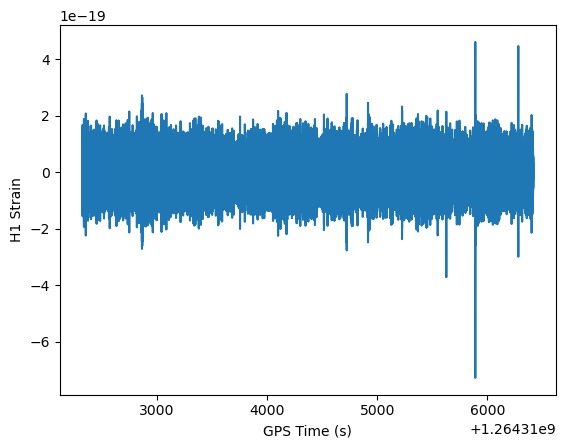

In [7]:
#---------------------
# Plot the time series
#---------------------
plt.plot(time, strain[()])
plt.xlabel('GPS Time (s)')
plt.ylabel('H1 Strain')
plt.show()

Por fim, vamos utilizar tudo isso para plotar alguns segundos de dados.
Como esses dados são amostrados a 4096 Hz, 10.000 amostras correspondem a cerca de 2,4 s.
Começaremos no instante 1256779566,0.

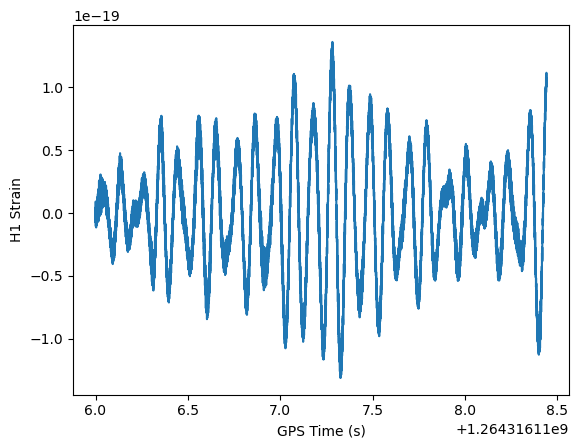

In [8]:
#------------------------
# Zoom in the time series
#------------------------
numsamples = 10000
startTime  = 1264316116.0
startIndex = np.min(np.nonzero(startTime < time))
time_seg   = time[startIndex:(startIndex+numsamples)]
strain_seg = strain[startIndex:(startIndex+numsamples)]
plt.plot(time_seg, strain_seg)
plt.xlabel('GPS Time (s)')
plt.ylabel('H1 Strain')
plt.show()

Você pode se surpreender ao ver que os dados parecem suaves e curvilíneos, em vez de irregulares e instáveis, como se poderia esperar para [ruído branco](https://en.wikipedia.org/wiki/White_noise).
Isso ocorre porque o ruído branco tem potência aproximadamente igual em todas as frequências, o que não acontece com os dados de ondas gravitacionais.
Em vez disso, os dados de ondas gravitacionais incluem ruído que é fortemente dependente da frequência - costumamos dizer que o ruído é "colorido" para distingui-lo do ruído branco.
As oscilações que você vê no gráfico acima estão na extremidade inferior da banda LVK (em torno de 20 Hz).

Em geral, o ruído de ondas gravitacionais é dominado por essas baixas frequências.

Para saber mais sobre o ruído de ondas gravitacionais em função da frequência, consulte o [Passo 4 desse tutorial](<04 - Working in Frequency Domain.ipynb>). 

### Um script um pouco mais avançado

Vamos escrever um pequeno script em Python para visualizar a estrutura *completa* de um arquivo de dados do GWOSC.
Baseia-se no método [visititems](https://docs.h5py.org/en/stable/high/group.html#h5py.Group.visititems).

In [9]:
def dump_info(name, obj):
    print("{0} :".format(name))
    try:
        print("   value: {0}".format(str(obj[()])))
        for key in obj.attrs.keys():
            print("     attrs[{0}]:  {1}".format(key, obj.attrs[key]))
    except:
        pass

file = h5py.File(filename)
file.visititems(dump_info)

meta :
meta/Description :
   value: b'Strain data time series from LIGO'
meta/DescriptionURL :
   value: b'http://www.gw-openscience.org/'
meta/Detector :
   value: b'H1'
meta/Duration :
   value: 4096
meta/FrameType :
   value: b'H1_HOFT_CLEAN_SUB60HZ_C01'
meta/GPSstart :
   value: 1264312320
meta/Observatory :
   value: b'H'
meta/StrainChannel :
   value: b'H1:DCS-CALIB_STRAIN_CLEAN_SUB60HZ_C01'
meta/Type :
   value: b'StrainTimeSeries'
meta/UTCstart :
   value: b'2020-01-29T05:51:42'
quality :
quality/detail :
quality/injections :
quality/injections/GWOSCmeta :
   value: b'GWOSC-4KHZ_R1_INJMASK'
quality/injections/InjDescriptions :
   value: [b'no cbc injection' b'no burst injections' b'no detchar injections'
 b'no continuous wave injections' b'no stoch injections']
quality/injections/InjShortnames :
   value: [b'NO_CBC_HW_INJ' b'NO_BURST_HW_INJ' b'NO_DETCHAR_HW_INJ' b'NO_CW_HW_INJ'
 b'NO_STOCH_HW_INJ']
quality/injections/Injmask :
   value: [23 23 23 ... 23 23 23]
     attrs[Bits]:

## Qual é o próximo passo?

No [próximo passo](<03 - Working with Data Quality.ipynb>), você aprenderá a trabalhar com data quality (qualidade de dados).